# Notebook 3 of 4 — A neural network with entity embeddings

In this notebook I build a neural network (an MLP) in PyTorch and compare it fairly with the tree models from
notebook 2.

**The idea: embeddings.** In notebook 2 every category got its own on/off switch (one-hot encoding). Switches are
all equally different from each other, so the model cannot see that "discharged to a nursing facility" and
"discharged to rehab" are similar places. An **embedding** gives every category a short list of numbers instead,
like map coordinates. The network learns these coordinates during training, and categories that behave alike end up
close together on the map.

```
[diagnosis group] → Embedding ─┐
[specialty]       → Embedding ─┤
[discharge]       → Embedding ─┤→ join → Linear → ReLU → Dropout → Linear → ReLU → Dropout → Linear → risk
 ... every other category      │
[numbers, scaled] ─────────────┘
```

---
## Step 0 — Setup and loading the prepared data

In [1]:
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RESULTS = ROOT / 'results'

d = joblib.load(RESULTS / 'prepared_data.joblib')
X_fit, y_fit = d['X_fit'], d['y_fit']
X_val, y_val = d['X_val'], d['y_val']
X_te = d['X_te']
cat_cols, num_cols = d['cat_cols'], d['num_cols']

---
## Step 4a — Turning categories into ID numbers

An embedding layer works like a lookup table: it needs every category as a whole number, so it knows which row of
coordinates to fetch. I give every value an ID (1, 2, 3, ...) and keep 0 for "a value I never saw during training".
I learn these IDs, and the scaling of the numeric columns, from FIT only, so nothing leaks in from VAL or TEST.

In [2]:
def fit_maps(data, cols):
    return {c: {v: i + 1 for i, v in enumerate(data[c].fillna('Missing').astype(str).unique())}
            for c in cols}

def encode(data, maps):
    return np.stack([data[c].fillna('Missing').astype(str).map(maps[c]).fillna(0).astype(int)
                     for c in maps], axis=1)

maps = fit_maps(X_fit, cat_cols)
scaler = StandardScaler().fit(X_fit[num_cols])

def to_tensors(data):
    return (torch.tensor(encode(data, maps), dtype=torch.long),
            torch.tensor(scaler.transform(data[num_cols]), dtype=torch.float32))

Xc_fit, Xn_fit = to_tensors(X_fit)
Xc_val, Xn_val = to_tensors(X_val)
Xc_te, Xn_te = to_tensors(X_te)
Y_fit = torch.tensor(y_fit.values, dtype=torch.float32)

# One extra ID per column for "unseen"
cards = [len(maps[c]) + 1 for c in cat_cols]
pd.Series(dict(zip(cat_cols, cards)), name='number of IDs').head(10)

race                         7
gender                       3
admission_type_id            9
discharge_disposition_id    22
admission_source_id         18
payer_code                  19
medical_specialty           68
diag_1_grp                  11
diag_2_grp                  11
diag_3_grp                  11
Name: number of IDs, dtype: int64

---
## Step 4b — The network

For each categorical column I create an embedding. Its size follows a common rule of thumb: half the number of
categories, at least 2 and at most 50. So `gender` (3 IDs) gets 2 coordinates, while `medical_specialty` (68 IDs)
gets 34.

All the embeddings are joined with the scaled numbers and passed through two hidden layers:
- **ReLU** keeps positive signals and sets negative ones to zero, which lets the network learn curved patterns.
- **Dropout** randomly switches off some neurons during training, like a team practising with random players
  missing, so no single neuron can carry the whole team. This reduces overfitting.

The network outputs one number per patient (a "logit"). The sigmoid function squeezes it into a risk between 0 and 1.

In [3]:
class EmbMLP(nn.Module):
    def __init__(self, cards, n_num, hidden=128, dropout=0.3):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(n, max(2, min(50, n // 2))) for n in cards])
        n_inputs = sum(e.embedding_dim for e in self.embs) + n_num
        self.net = nn.Sequential(
            nn.Linear(n_inputs, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden // 2, 1))

    def forward(self, xc, xn):
        e = torch.cat([emb(xc[:, i]) for i, emb in enumerate(self.embs)], dim=1)
        return self.net(torch.cat([e, xn], dim=1)).squeeze(1)

demo = EmbMLP(cards, len(num_cols))
print('Trainable parameters:', sum(p.numel() for p in demo.parameters()))

Trainable parameters: 30968


---
## Step 4c — Training with class weighting and early stopping

Two ideas keep the training sensible:

- **Class weighting:** `pos_weight` (about 8) makes every readmitted patient count about 8 times in the loss, the same
  idea as in notebook 2.
- **Early stopping:** after every pass over the data (an *epoch*) I check PR-AUC on VAL. If it has not improved for
  4 epochs, I stop and go back to the best epoch. It is like taking a cake out of the oven when it stops rising,
  before it burns: training longer would make the network memorise FIT instead of learning general patterns.

In [4]:
def predict_proba(model, xc, xn):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(xc, xn)).numpy()

def train_mlp(lr=1e-3, hidden=128, dropout=0.3, seed=SEED, epochs=30, patience=4):
    torch.manual_seed(seed)
    model = EmbMLP(cards, Xn_fit.shape[1], hidden, dropout)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    pos_w = torch.tensor((y_fit == 0).sum() / (y_fit == 1).sum(), dtype=torch.float32)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    loader = DataLoader(TensorDataset(Xc_fit, Xn_fit, Y_fit), batch_size=512, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    best_ap, best_state, best_epoch, wait = -1, None, 0, 0
    for epoch in range(1, epochs + 1):
        model.train()
        for xc, xn, yb in loader:
            opt.zero_grad()
            loss_fn(model(xc, xn), yb).backward()
            opt.step()

        # I keep the epoch with the best VAL score and stop when it no longer improves
        ap = average_precision_score(y_val, predict_proba(model, Xc_val, Xn_val))
        if ap > best_ap:
            best_ap, best_state, best_epoch, wait = ap, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return model, best_ap, best_epoch

---
## Step 4d — A small random search

I try 5 random combinations of learning rate (how big each learning step is), hidden size (how many neurons) and
dropout, and keep the one with the best VAL PR-AUC.

In [5]:
rng = np.random.default_rng(SEED)
rows = []
for i in range(5):
    cfg = {'lr': float(10 ** rng.uniform(-3.5, -2.5)),
           'hidden': int(rng.choice([64, 128, 256])),
           'dropout': float(rng.choice([0.1, 0.3, 0.5]))}
    _, ap, ep = train_mlp(**cfg)
    rows.append({**cfg, 'best epoch': ep, 'VAL PR-AUC': round(ap, 4)})

mlp_search = pd.DataFrame(rows).sort_values('VAL PR-AUC', ascending=False)
mlp_search

,lr,hidden,dropout,best epoch,VAL PR-AUC
3,0.001824,256,0.5,18,0.2318
2,0.000393,128,0.5,28,0.2310
0,0.001879,128,0.3,10,0.2300
1,0.002283,64,0.5,16,0.2281
4,0.000425,256,0.3,10,0.2213


All five settings land close together (VAL PR-AUC about 0.22–0.23), so the network is not very sensitive to these
choices. The best one uses the larger hidden layer with strong dropout.

### Repeating the best setting with 3 seeds

A neural network starts from random weights, so one run can be lucky. I train the winning setting three times with
different random starts. The spread (± value) is the network's version of the cross-validation spread in notebook 2.

In [6]:
best_cfg = mlp_search.iloc[0][['lr', 'hidden', 'dropout']].to_dict()
best_cfg['hidden'] = int(best_cfg['hidden'])

seed_scores, models = [], {}
for s in [SEED, SEED + 1, SEED + 2]:
    models[s], ap, _ = train_mlp(**best_cfg, seed=s)
    seed_scores.append(ap)

print('Best settings:', best_cfg)
print('VAL PR-AUC per seed:', [round(a, 4) for a in seed_scores])
print(f'Mean ± sd: {np.mean(seed_scores):.3f} ± {np.std(seed_scores):.3f}')
mlp = models[SEED]

Best settings: {'lr': 0.0018244824996578725, 'hidden': 256, 'dropout': 0.5}
VAL PR-AUC per seed: [0.2318, 0.2219, 0.2224]
Mean ± sd: 0.225 ± 0.005


The network reaches about 0.22–0.23 on VAL, close to the tree models in notebook 2.

**Keeping the comparison fair.** All four models are scored on the same TEST set with the same measures in
notebook 4, and all of them deal with the rare class. The network had a smaller tuning budget (5 settings) than the
trees. VAL was used both for early stopping and for choosing settings, so the VAL score above is a little optimistic;
the TEST score in notebook 4 is the honest one. Research also shows that neural networks on table data often do not
beat gradient-boosted trees (Grinsztajn et al., 2022), so my aim here is a fair comparison, not a guaranteed winner.

### Saving the predictions

I save the network's risk scores for VAL and TEST. I do not look at the TEST scores here; they are compared with
the other models in notebook 4.

In [7]:
mlp_out = {
    'p_val': predict_proba(mlp, Xc_val, Xn_val),
    'p_te': predict_proba(mlp, Xc_te, Xn_te),
    'best_cfg': best_cfg,
    'seed_scores': seed_scores,
}
joblib.dump(mlp_out, RESULTS / 'mlp_predictions.joblib')
print('Saved results/mlp_predictions.joblib')

Saved results/mlp_predictions.joblib


---
## Step 4f — Looking inside one embedding

Each discharge destination now has learned coordinates. I squash them down to 2 dimensions with PCA (like taking a
photo of a 3-D object, which keeps as much of the shape as possible on a flat page) and label each point with its
name from the code book. I only show destinations with at least 100 patients in FIT, because the coordinates of very
rare codes are mostly noise.

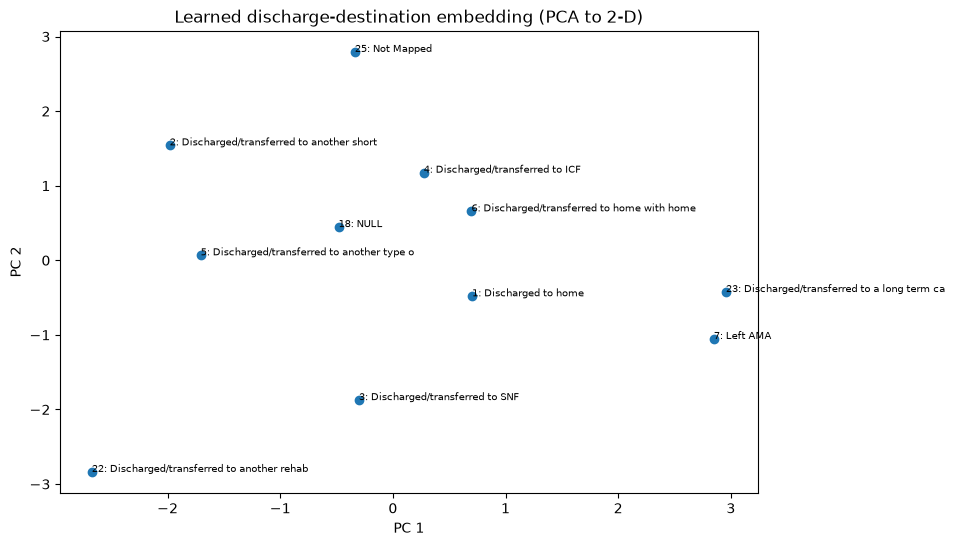

In [8]:
col = 'discharge_disposition_id'
weights = mlp.embs[cat_cols.index(col)].weight.detach().numpy()
counts = X_fit[col].value_counts()
names = d['id_mapping']['discharge_disposition_id']

codes = [c for c in maps[col] if counts.get(c, 0) >= 100]
vectors = weights[[maps[col][c] for c in codes]]
xy = PCA(n_components=2, random_state=SEED).fit_transform(vectors)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(xy[:, 0], xy[:, 1])
for (x0, y0), c in zip(xy, codes):
    ax.annotate(f'{c}: {names.get(c, "?")[:40]}', (x0, y0), fontsize=7)
ax.set_title('Learned discharge-destination embedding (PCA to 2-D)')
ax.set_xlabel('PC 1')
ax.set_ylabel('PC 2')
plt.show()

The map is only partly tidy. Destinations that involve further care, such as a nursing facility (SNF, code 3) and
rehab (code 22), sit in the lower part of the map, away from "discharged to home" (code 1). Other codes do not form
clear clusters. Many destinations have only a few hundred patients, so I read this picture as a hint that the network
learned some meaningful similarity, not as proof.